<a href="https://colab.research.google.com/github/shubhamjadoun5-source/basic_project/blob/main/Project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
# Load the dataset
df = pd.read_csv('/content/AB_NYC_2019.csv')

In [5]:
print("--- First 5 Rows (Head) ---")
display(df.head())

--- First 5 Rows (Head) ---


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,0.00,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [6]:
# Display the last 5 rows
print("\n--- Last 5 Rows (Tail) ---")
display(df.tail())


--- Last 5 Rows (Tail) ---


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,0.0,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,0.0,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,0.0,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,0.0,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,0.0,1,23


In [8]:
# Display dataset information
print("--- Dataset Info ---")
df.info()


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review

In [9]:
# Check for duplicate values
duplicate_count = df.duplicated().sum()
print(f"\nTotal duplicate rows: {duplicate_count}")


Total duplicate rows: 0


In [10]:
# Check for missing values
print("\n--- Missing Values ---")
display(df.isnull().sum())


--- Missing Values ---


,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


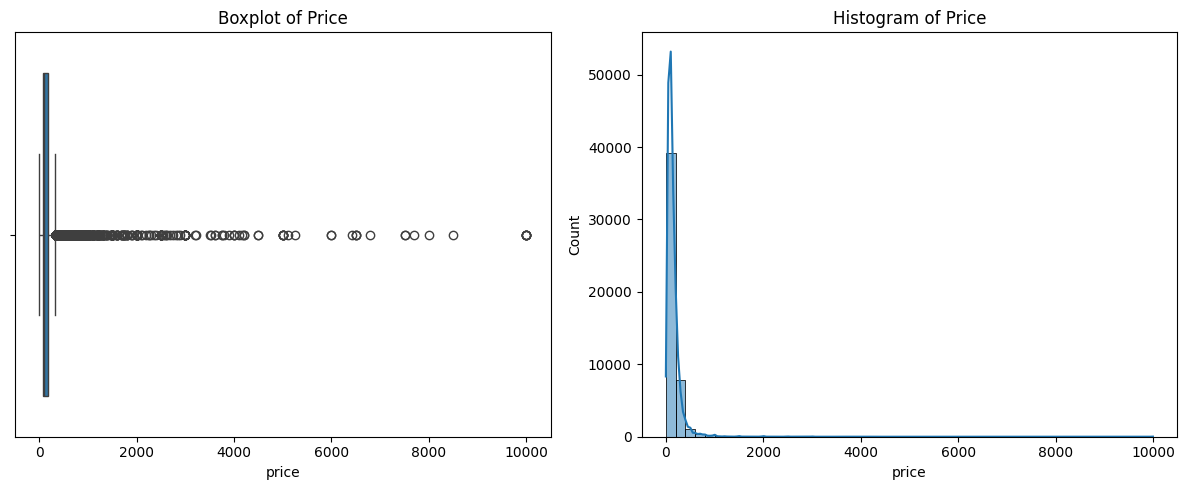

In [3]:
# 2. Data Cleaning & Outlier Visualization

# Drop duplicates if any
df = df.drop_duplicates()

# Fill missing values for numerical / categorical columns we might use
# For simplicity in this demo, we will use 'price' as target, and 'minimum_nights', 'number_of_reviews', 'reviews_per_month' as features.
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# Visualize outliers in 'price' using boxplot and histogram
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['price'])
plt.title('Boxplot of Price')

plt.subplot(1, 2, 2)
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Histogram of Price')

plt.tight_layout()
plt.show()

In [13]:
from sklearn.model_selection import train_test_split

# Selecting independent features (X) and target variable (y)
features = ['minimum_nights', 'number_of_reviews', 'reviews_per_month']
X = df[features]
y = df['price']


In [14]:
# Splitting the dataset (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (39116, 3)
Testing set shape: (9779, 3)


In [11]:
# Drop metadata and high-cardinality neighborhood column
cols_to_drop = ['id', 'name', 'host_id', 'host_name', 'neighbourhood']
df_clean = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

# Logically fill reviews_per_month with 0 if missing
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)

# Cap price and minimum_nights outliers at the 95th percentile
price_cap = df_clean['price'].quantile(0.95)
min_nights_cap = df_clean['minimum_nights'].quantile(0.95)

df_clean['price'] = np.where(df_clean['price'] > price_cap, price_cap, df_clean['price'])
df_clean['minimum_nights'] = np.where(df_clean['minimum_nights'] > min_nights_cap, min_nights_cap, df_clean['minimum_nights'])

# One-Hot Encoding for neighbourhood_group and room_type
df_clean = pd.get_dummies(df_clean, columns=['neighbourhood_group', 'room_type'], drop_first=True)

display(df_clean.head())

,latitude,longitude,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149.0,1.0,9,2018-10-19,0.21,6,365,True,False,False,False,True,False
1,40.75362,-73.98377,225.0,1.0,45,2019-05-21,0.38,2,355,False,True,False,False,False,False
2,40.80902,-73.94190,150.0,3.0,0,NaN,0.00,1,365,False,True,False,False,True,False
3,40.68514,-73.95976,89.0,1.0,270,2019-07-05,4.64,1,194,True,False,False,False,False,False
4,40.79851,-73.94399,80.0,10.0,9,2018-11-19,0.10,1,0,False,True,False,False,False,False


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Separate features and target, ensuring we drop non-numeric columns like 'last_review'
X_clean = df_clean.drop(columns=['price', 'last_review'], errors='ignore')
y_clean = df_clean['price']

# Train-Test Split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

# Train Linear Regression
model = LinearRegression()
model.fit(X_train_c, y_train_c)

# Predict on Test Set
y_pred_c = model.predict(X_test_c)

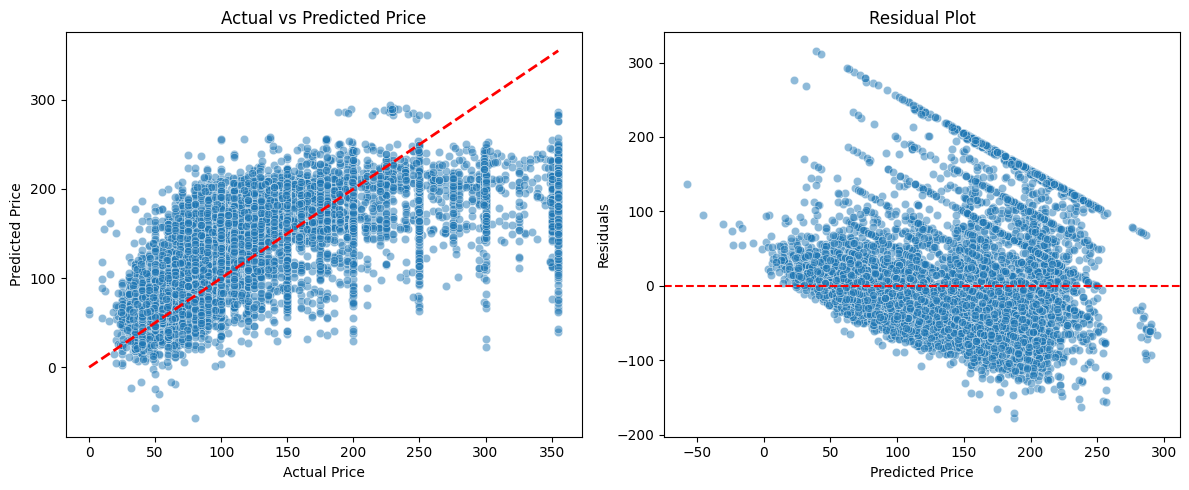

In [18]:
residuals = y_test_c - y_pred_c

plt.figure(figsize=(12, 5))

# Actual vs Predicted with 45 degree line
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_test_c, y=y_pred_c, alpha=0.5)
plt.plot([y_test_c.min(), y_test_c.max()], [y_test_c.min(), y_test_c.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Price')

# Residual plot
plt.subplot(1, 2, 2)
sns.scatterplot(x=y_pred_c, y=residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.tight_layout()
plt.show()